# Use case

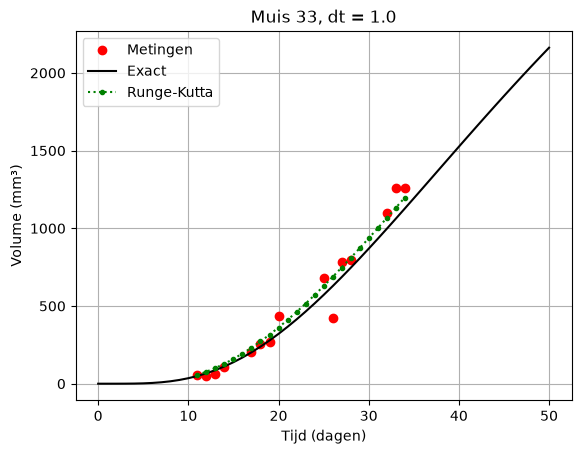

In [1]:
from package.models import *
from package.random_search import random_search

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
data = pd.read_csv("test_data/LM2-4LUC.txt", sep="\t")

muis33 = data[data["ID"] == 33]
muis34 = data[data["ID"] == 34]
muis35 = data[data["ID"] == 35]

In [4]:
def plot_test_data(data, marker_size = None, title = None):
    if marker_size:
        plt.scatter(x= data["Time"], y = data["Observation"], s = marker_size)
    else:
        plt.scatter(x= data["Time"], y = data["Observation"])
    plt.ylabel("Volume ($mm^3$)")
    plt.xlabel("Time (days) after implantation")
    plt.grid(visible = True)
    plt.ylim(bottom=0)
    plt.axvline(0.0, color='k') # maakt een verticale zwarte lijn op de x = 0
    if title:
        plt.title(title)

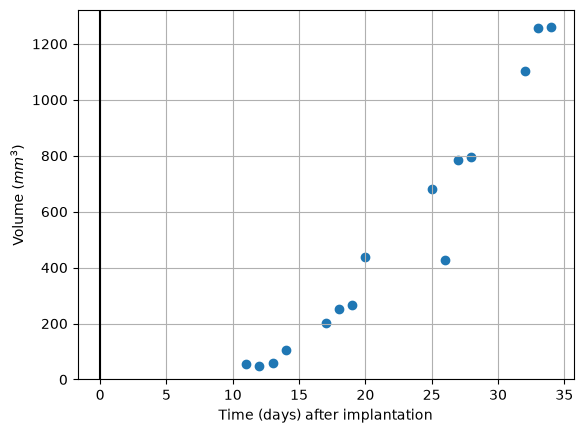

In [5]:
plot_test_data(muis33)

In [6]:
t_data = muis33["Time"].values
V_data = muis33["Observation"].values

mse, params_random = random_search(t_data, V_data, bertalanffy, dt = 1, alpha = 0, beta = 0)
print(mse)
print(params_random)

5599.932668150582
{'alpha': 1.2315816505648636, 'beta': 0.041417561821883116}


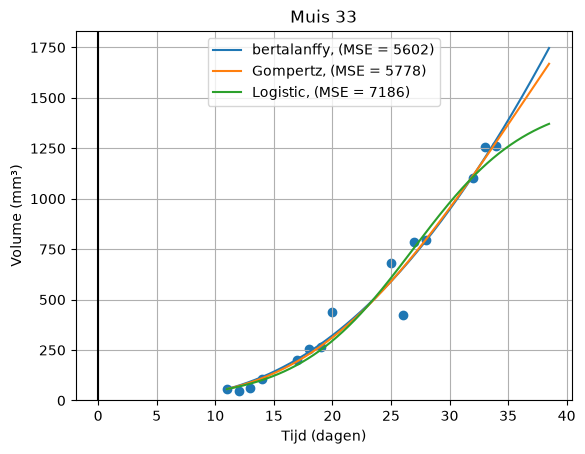

In [8]:
from package.test_runge_kutta import runge_kutta  # TODO de functie voor runge_kutta uit test_runge_kutta halen

dt = .1
t_start = t_data[0]
V_start = V_data[0]
n_steps = 275

for model, naam in [(bertalanffy, "bertalanffy"), (gompertz, "Gompertz")]:
    mse, params = random_search(t_data, V_data, model, dt = 1, alpha = 0, beta = 0)
    ts, Vs = runge_kutta(model, t_start, V_start, dt, n_steps, **params)
    plt.plot(ts, Vs, label=f"{naam}, (MSE = {mse:.0f})")
for model, naam in [(logistic, "Logistic")]:
    mse, params = random_search(t_data, V_data, model, dt = 1, alpha = 1.5, beta = 1500)  # logistic heeft andere start waarden nodig
    ts, Vs = runge_kutta(model, t_start, V_start, dt, n_steps, **params)
    plt.plot(ts, Vs, label=f"{naam}, (MSE = {mse:.0f})")
plot_test_data(muis33)
plt.xlabel("Tijd (dagen)")
plt.ylabel("Volume (mm³)")
plt.title("Muis 33")
plt.grid(True)
plt.legend()
plt.show()

TODO model_comparison.py functies laten zien